In [2]:
%pip install earthaccess

  Obtaining dependency information for earthaccess from https://files.pythonhosted.org/packages/0c/88/386bbc53666cd7b54144d258a1bcb2753a89404b14f5f043c44b200f3b48/earthaccess-0.17.0-py3-none-any.whl.metadata
  Obtaining dependency information for fsspec>=2025.2 from https://files.pythonhosted.org/packages/6c/c0/a98505f18594f1bce828bb159cec0fcf9860562f1a2c85913409fc8f3d9e/fsspec-2026.9.0-py3-none-any.whl.metadata
  Obtaining dependency information for importlib-resources>=6.3.2 from https://files.pythonhosted.org/packages/8a/db/55a262f3606bebcae07cc14095338471ad7c0bbcaa37707e6f0ee49725b7/importlib_resources-7.1.0-py3-none-any.whl.metadata
  Obtaining dependency information for multimethod>=1.8 from https://files.pythonhosted.org/packages/a7/9e/3538af4267d2e29d871e7a1ae390e8ff32122b3c560fe718569c4cd7624a/multimethod-2.1-py3-none-any.whl.metadata
  Obtaining dependency information for pqdm>=0.1 from https://files.pythonhosted.org/packages/9e/b7/720988acdc9b5805cd1ef311aa75d6fd1c5438b87f4a

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 552.6/552.6 kB 11.7 MB/s eta 0:00:00 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 12.4 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.1/52.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.0/104.0 kB 9.7 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2023.4.0
    Uninstalling fsspec-2023.4.0:
      Successfully uninstalled fsspec-2023.4.0
  Attempting uninstall: aiosignal
    Found existing installation: aiosignal 1.2.0
    Uninstalling aiosignal-1.2.0:
      Successfully uninstalled aiosignal-1.2.0
  Attempting uninstall: yarl
    Found existing installation: yarl 1.8.1
    Uninstalling yarl-1.8.1:
      Successfully uninstalled yarl-1.8.1
  Attempting u

In [17]:
import earthaccess
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path

# settings
YEAR = 2020          
TEST_MODE = False      # True = download 1 week only; False = full JJAS

if TEST_MODE:
    start, end, expected = f"{YEAR}-06-01", f"{YEAR}-06-07", 7
else:
    start, end, expected = f"{YEAR}-06-01", f"{YEAR}-06-30", 30
raw_dir = Path("data/raw/imerg")
out_dir = Path("data/processed")
raw_dir.mkdir(parents=True, exist_ok=True)
out_dir.mkdir(parents=True, exist_ok=True)

# 1. Log in
# Earthdata username and password the first time.
earthaccess.login(persist=True)

# 2. Search
results = earthaccess.search_data(
    short_name="GPM_3IMERGDF",
    version="07",
    temporal=(start, end),
    bounding_box=(74, 8, 78, 13),   # west, south, east, north
)
print(f"Files found: {len(results)} (expected {expected})")
assert len(results) == expected, "File count is wrong, check dates/product name"

# 3. Download 
files = earthaccess.download(results, str(raw_dir))
print(f"Files downloaded: {len(files)}")

# 4. Open, crop to Kerala
ds = xr.open_mfdataset(files)
rain = ds["precipitation"]

# Handle ascending or descending latitude
lat_slice = slice(8, 13) if ds.lat[0] < ds.lat[-1] else slice(13, 8)
kerala = rain.sel(lon=slice(74, 78), lat=lat_slice)

# 5. Quick checks
print("Shape (time, lon, lat or similar):", kerala.shape)
print("Min / max (mm/day):", float(kerala.min()), float(kerala.max()))
print("Fraction NaN:", float(kerala.isnull().mean()))

#  6. Save
out_name = f"imerg_kerala_{start}_{end}.nc"
kerala.to_netcdf(out_dir / out_name)
print("Saved:", out_dir / out_name)

Files found: 30 (expected 30)


/Users/jazanowrin/anaconda3/lib/python3.11/site-packages/earthaccess/results.py:343: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
/Users/jazanowrin/anaconda3/lib/python3.11/site-packages/earthaccess/store.py:832: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum(granule.size() for granule in granules) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/30 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/30 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/30 [00:00<?, ?it/s]

Files downloaded: 30
Shape (time, lon, lat or similar): (30, 40, 50)
Min / max (mm/day): 0.0 176.76498413085938
Fraction NaN: 0.0
Saved: data/processed/imerg_kerala_2020-06-01_2020-06-30.nc


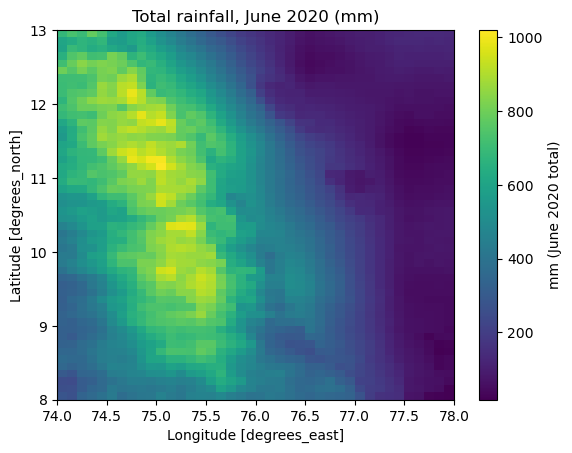

In [18]:
kerala.sum("time").T.plot(cbar_kwargs={"label": "mm (June 2020 total)"})
plt.title("Total rainfall, June 2020 (mm)")
plt.show()